# Pairwise Dissimilarity Representation for One-Class Signature Verification
### Experiment v3 — genuine-only writer-adaptive calibration in a pair space

**Lineage:** `6buwan` (raw pixels against HOG) → `v1` (calibration, degenerate kernels)
→ `v2` (kernel constrained, method failed) → **`v3` (pairwise representation)**

## Rationale

v2 resolved a question by failing cleanly. With the kernel constrained to remain
non-degenerate:

| v2 constrained | RAW | HOG |
|---|---|---|
| writers meeting acceptance target | **0 / 55** | **0 / 55** |
| mean LOO acceptance | 0.239 | 0.220 |
| FRR against fixed baseline | 0.836 vs 0.796 (worse, p = 0.005) | 0.841 vs 0.814 (worse, p = 0.007) |
| sweep across targets 0.50 → 0.90 | **flat** | **flat** |

The flat sweep is the diagnostic: moving the risk target changed nothing, because no
candidate ever qualified and every writer received the same fallback. v1's apparent
improvement, FRR 0.81 → 0.43, arose from γ collapsing to approximately 1e-11, where
exp(−γd²) ≈ 1 for every pair and the RBF kernel ceases to measure distance.

**The constraint is geometric rather than parametric.** Twelve points cannot define a
boundary in 4,356 dimensions. An AUC of 0.95 establishes that the discriminative
information is present; a leave-one-out acceptance of 0.22 establishes that no
one-class boundary can capture it from twelve samples. No choice of ν and γ alters
that.

## What this version changes

The one-class SVM is trained on **pairwise similarity descriptors between
signatures** rather than on signature vectors.

| | v2 | v3 |
|---|---|---|
| training samples per writer | 12 | **66** (all pairs of 12) |
| dimensionality | 4,356 (HOG) / 10,000 (raw) | **16** |
| what a sample represents | one signature | similarity between two signatures of one writer |

Two constraints are addressed simultaneously: 5.5 times more training data, in a space
small enough for that data to define a boundary.

**Verification.** The questioned signature is paired with each of the twelve enrolled
signatures, all twelve pairs are classified, and the decision is taken by majority
vote. The continuous score for ROC-AUC is the mean decision function.

## Provenance

The pairwise-space formulation is prior work. Starovoitov and Akhundjanov (2024)
introduced it for this problem, reaching 99.77% on CEDAR from 5 to 15 signatures,
using local binary patterns and contour curvature with rank-correlation coordinates.
This experiment adopts that formulation and cites it as prior work.

The contribution under test remains the calibration. Guerbai et al. (2015) identified
boundary placement under limited samples as the failure mode and addressed it with a
global soft threshold, stating that "the parameters are the same for all writers. This
avoids calculating the parameters for each writer." Starovoitov and Akhundjanov (2024)
construct the pairwise space but do not individualise hyperparameters; their stated
contribution is "new features and a new feature space." No prior work identified
performs genuine-only per-writer hyperparameter calibration inside such a space.

## Checkpoint structure

The decisive question is answered early and cheaply.

- **Checkpoint A (Part 5)** — does a fixed-hyperparameter one-class SVM in pair space
  resolve the 0.22 acceptance problem? A negative result here means the representation
  is not the answer and nothing downstream is interpretable.
- **Checkpoint B (Part 9)** — does per-writer calibration add anything on top of a
  working pair-space baseline?

Both are reported as explicit PASS or FAIL verdicts.

---
## Part 0 — Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np, pandas as pd
from PIL import Image, ImageOps
from math import floor, ceil
from skimage.feature import hog
from skimage.filters import threshold_otsu
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score
from scipy import stats
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import random, time, itertools
from pathlib import Path

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)

NB_T0 = time.time(); SECTION_TIMES = {}
def mark(section):
    now = time.time(); prev = SECTION_TIMES.get("_last", NB_T0)
    SECTION_TIMES[section] = now - prev; SECTION_TIMES["_last"] = now
    print(f"[timer] {section}: {now-prev:.1f}s   (total {now-NB_T0:.1f}s)")

print("Imports loaded. Seed =", RANDOM_SEED)
print("NOTE: scikit-learn is CPU-only. Use a CPU + High-RAM runtime; GPU/TPU do nothing here.")

Imports loaded. Seed = 42
NOTE: scikit-learn is CPU-only. Use a CPU + High-RAM runtime; GPU/TPU do nothing here.


In [ ]:
DATASET_DIR = Path("/content/drive/MyDrive/cedar-dataset/signatures")
GENUINE_DIR = DATASET_DIR / "full_org"
FORGED_DIR  = DATASET_DIR / "full_forg"

IMG_SIZE        = (100, 100)
MAX_CROP_ASPECT = 2.5
DENSITY_FRAC    = 0.05
N_WRITERS       = 55
N_TRAIN_GENUINE = 12

# pair-space OCSVM defaults for the CHECKPOINT A baseline (shared across all writers)
PAIR_BASELINE = {"nu": 0.10, "gamma": "scale"}

# calibration targets
TARGET_ACCEPT        = 0.70
TARGET_COHORT_REJECT = 0.95
COHORT_WRITERS       = 20     # other writers sampled as surrogate impostors
KERNEL_SCALE_MIN     = 0.01   # retained from v2; pair space is low-dim so this should bind far less

print("Config set.")

Config set.


---
## Part 1 — Data, split, preprocessing, features *(unchanged from v2)*

In [4]:
genuine_files = sorted(GENUINE_DIR.glob("*.png"))
forged_files  = sorted(FORGED_DIR.glob("*.png"))
def get_writer_id(fp): return int(Path(fp).stem.split("_")[1])
assert len(genuine_files) == 1320 and len(forged_files) == 1320
print("Files OK:", len(genuine_files), "genuine /", len(forged_files), "forged")

rng_split = random.Random(RANDOM_SEED); writer_splits = {}
for wid in range(1, N_WRITERS+1):
    g = sorted([p for p in genuine_files if get_writer_id(p)==wid])
    f = sorted([p for p in forged_files  if get_writer_id(p)==wid])
    sg = g.copy(); rng_split.shuffle(sg); sf = f.copy(); rng_split.shuffle(sf)
    writer_splits[wid] = {"train_genuine": sg[:N_TRAIN_GENUINE],
                          "test_genuine":  sg[N_TRAIN_GENUINE:],
                          "test_forged":   sf}
for s in writer_splits.values():
    assert len(s["train_genuine"])==12 and len(s["test_genuine"])==12 and len(s["test_forged"])==24
print("Split OK -- 12 train / 12 test genuine / 24 test forged per writer")
mark("Part 1a split")

Files OK: 1320 genuine / 1320 forged
Split OK -- 12 train / 12 test genuine / 24 test forged per writer
[timer] Part 1a split: 19.2s   (total 19.2s)


In [5]:
def _common_geometry(img, max_aspect=MAX_CROP_ASPECT, density_frac=DENSITY_FRAC, img_size=IMG_SIZE):
    tw, th = img_size
    ink = img > threshold_otsu(img) if img.max() > img.min() else np.zeros_like(img, bool)
    if ink.any():
        rc, cc = ink.sum(1), ink.sum(0)
        sr = rc >= max(2, rc.max()*density_frac); sc = cc >= max(2, cc.max()*density_frac)
        if sr.any() and sc.any():
            t,b = np.where(sr)[0][[0,-1]]; l,r = np.where(sc)[0][[0,-1]]
            img = img[t:b+1, l:r+1]
    h,w = img.shape
    if w/h > max_aspect:
        pad = max(0, ceil(w/max_aspect)-h); img = np.pad(img, ((pad//2, pad-pad//2),(0,0)), constant_values=0)
    elif h/w > max_aspect:
        pad = max(0, ceil(h/max_aspect)-w); img = np.pad(img, ((0,0),(pad//2, pad-pad//2)), constant_values=0)
    h,w = img.shape
    nw = min(tw, max(1, w*th//h)); nh = max(1, h*nw//w)
    img = np.asarray(Image.fromarray(img.astype(np.uint8)).resize((nw,nh)))
    top=floor((th-nh)/2); bot=ceil((th-nh)/2); lef=floor((tw-nw)/2); rig=ceil((tw-nw)/2)
    return np.pad(img, ((top,bot),(lef,rig)), mode="constant", constant_values=0)

def preprocess_signature(path):
    with Image.open(path) as im:
        return _common_geometry(np.asarray(ImageOps.invert(im.convert("L"))))

HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2), block_norm="L2-Hys")
def raw_feature_fn(i01): return i01.flatten()
def hog_feature_fn(i01): return hog(i01, **HOG_PARAMS)

def build_features(paths, fn):
    return np.array([fn(preprocess_signature(p).astype(np.float32)/255.0) for p in paths])

train_files        = [p for s in writer_splits.values() for p in s["train_genuine"]]
test_genuine_files = [p for s in writer_splits.values() for p in s["test_genuine"]]
test_forged_files  = [p for s in writer_splits.values() for p in s["test_forged"]]

print("Extracting features...")
F = {}
for rep, fn in [("RAW", raw_feature_fn), ("HOG", hog_feature_fn)]:
    F[rep] = {"train":    build_features(train_files, fn),
              "test_gen": build_features(test_genuine_files, fn),
              "test_for": build_features(test_forged_files, fn)}
    print(f"  {rep}: {F[rep]['train'].shape}")
mark("Part 1b features")

Extracting features...
  RAW: (660, 10000)
  HOG: (660, 4356)
[timer] Part 1b features: 1707.7s   (total 1727.0s)


---
## Part 2 — The pairwise similarity descriptor

Maps an ordered pair of signature feature vectors to a short vector of similarity
measures. Several complementary measures are used rather than a single distance,
because any one of them discards information the others retain — correlation is
scale-invariant, Euclidean distance is not; rank correlation is robust to outlier
dimensions, Pearson is not; histogram measures suit HOG's binned structure.

Block-wise correlations add coarse spatial locality: the feature vector is split into
`N_BLOCKS` contiguous segments and correlated segment-wise, so a pair that agrees
globally but disagrees in one region is distinguishable from one that agrees
throughout.

**The descriptor is symmetric** — `d(a,b) == d(b,a)` — so a pair has one
representation regardless of ordering.

In [6]:
N_BLOCKS = 8

def pair_descriptor(a, b, n_blocks=N_BLOCKS):
    """Symmetric similarity descriptor for two signature feature vectors."""
    a = np.asarray(a, dtype=np.float64); b = np.asarray(b, dtype=np.float64)
    eps = 1e-12
    out = []

    # cosine similarity
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    out.append(float(a @ b / (na*nb + eps)))

    # Pearson correlation
    am, bm = a - a.mean(), b - b.mean()
    out.append(float(am @ bm / (np.linalg.norm(am)*np.linalg.norm(bm) + eps)))

    # Spearman rank correlation (robust; the Starovoitov-style coordinate)
    rho = spearmanr(a, b).correlation
    out.append(float(rho) if np.isfinite(rho) else 0.0)

    # normalised Euclidean distance
    out.append(float(np.linalg.norm(a-b) / (na + nb + eps)))

    # mean absolute difference, and its dispersion
    d = np.abs(a-b)
    out.append(float(d.mean()))
    out.append(float(d.std()))

    # histogram-style measures (meaningful for HOG; defined for RAW after shifting)
    ap, bp = np.clip(a, 0, None), np.clip(b, 0, None)
    sa, sb = ap.sum() + eps, bp.sum() + eps
    ap, bp = ap/sa, bp/sb
    out.append(float(np.minimum(ap, bp).sum()))                       # intersection
    out.append(float(0.5 * ((ap-bp)**2 / (ap+bp+eps)).sum()))         # chi-square

    # block-wise Pearson correlations -> coarse spatial locality
    for ablk, bblk in zip(np.array_split(a, n_blocks), np.array_split(b, n_blocks)):
        x, y = ablk - ablk.mean(), bblk - bblk.mean()
        out.append(float(x @ y / (np.linalg.norm(x)*np.linalg.norm(y) + eps)))

    return np.array(out, dtype=np.float64)


PAIR_DIM = len(pair_descriptor(np.random.rand(100), np.random.rand(100)))
print(f"Pair descriptor dimension: {PAIR_DIM}")
print(f"  8 global measures + {N_BLOCKS} block correlations")
print(f"\nPer writer: C(12,2) = {12*11//2} genuine training pairs in {PAIR_DIM}-D")
print(f"  compare v2: 12 samples in 4,356-D (HOG)")
print(f"  samples-per-dimension: v3 = {66/PAIR_DIM:.1f}   v2 = {12/4356:.4f}")

Pair descriptor dimension: 16
  8 global measures + 8 block correlations

Per writer: C(12,2) = 66 genuine training pairs in 16-D
  compare v2: 12 samples in 4,356-D (HOG)
  samples-per-dimension: v3 = 4.1   v2 = 0.0028


In [7]:
# ============================================================================
#  PAIR CACHING  -- the descriptors never change during calibration, only the
#  OCSVM hyperparameters do. Computing them once per writer instead of inside
#  every leave-one-out fold is the difference between minutes and hours:
#  spearmanr over a 4,356-dim vector is expensive and was being recomputed
#  tens of thousands of times.
# ============================================================================

def genuine_pair_cache(X_writer_train):
    """
    Compute every within-writer pair descriptor ONCE.

    Returns (D, idx) where D[k] is the descriptor for pair idx[k] = (i, j), i<j.
    Every leave-one-out fold is a SUBSET of this same cache, so no descriptor is
    ever computed twice.
    """
    n = len(X_writer_train)
    idx = list(itertools.combinations(range(n), 2))
    D = np.array([pair_descriptor(X_writer_train[i], X_writer_train[j]) for i, j in idx])
    return D, idx


def loo_subsets(idx, n, held_out):
    """Row masks into the cached pair matrix for one LOO fold."""
    train_mask = np.array([held_out not in p for p in idx])
    query_mask = np.array([held_out in p for p in idx])
    return train_mask, query_mask


def query_pair_cache(x_query, X_writer_train):
    """Descriptors pairing one questioned signature against every enrolled signature."""
    return np.array([pair_descriptor(x_query, t) for t in X_writer_train])


print("Pair cache helpers defined.")

Pair cache helpers defined.


---
## Part 3 — Verification protocol in pair space

A questioned signature is paired with each of the 12 enrolled signatures, every pair is
classified, and the decision is taken by **majority vote**: more outlier pairs than
half means forged.

The continuous score used for ROC-AUC is the **mean decision function** over the 12
pairs, which is the natural threshold-free analogue of that vote.

In [8]:
def _decide(preds):
    return 1 if int((preds == 1).sum()) > len(preds)/2 else -1


def fit_from_pairs(P):
    """Fit scaler + OCSVM from a cached pair-descriptor matrix. Returns (model, scaler)."""
    sc = StandardScaler().fit(P)
    return None, sc   # placeholder; model fitted by fit_pairs_params


def fit_pairs_params(P, nu, gamma):
    sc = StandardScaler().fit(P)
    m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(sc.transform(P))
    return m, sc


def verify_cached(model, scaler, Q):
    """Q: cached (n_enrolled, PAIR_DIM) query-pair matrix. Returns (decision, score)."""
    Qs = scaler.transform(Q)
    return _decide(model.predict(Qs)), float(model.decision_function(Qs).mean())


def fit_writer(X_writer_train, nu, gamma):
    """Convenience wrapper (uncached) -- used only outside the hot loops."""
    D, _ = genuine_pair_cache(X_writer_train)
    m, sc = fit_pairs_params(D, nu, gamma)
    return m, sc, D


def verify(model, scaler, x_query, X_writer_train):
    return verify_cached(model, scaler, query_pair_cache(x_query, X_writer_train))


def _widx(files, wid): return [i for i, p in enumerate(files) if get_writer_id(p) == wid]


def evaluate_pairspace(rep, params, label=""):
    """params: {'nu','gamma'} shared, or {wid: {'nu','gamma'}} per writer."""
    Xtr, Xtg, Xtf = F[rep]["train"], F[rep]["test_gen"], F[rep]["test_for"]
    rows = []
    for wid in range(1, N_WRITERS+1):
        tr = _widx(train_files, wid); tg = _widx(test_genuine_files, wid); tf = _widx(test_forged_files, wid)
        W = Xtr[tr]
        pr = params[wid] if wid in params else params
        D, _ = genuine_pair_cache(W)
        m, sc = fit_pairs_params(D, pr["nu"], pr["gamma"])

        gd, gs = zip(*[verify_cached(m, sc, query_pair_cache(Xtg[i], W)) for i in tg])
        fd, fs = zip(*[verify_cached(m, sc, query_pair_cache(Xtf[i], W)) for i in tf])
        gd, fd = np.array(gd), np.array(fd)

        tp=int((gd==1).sum()); fn=int((gd==-1).sum()); fp=int((fd==1).sum()); tn=int((fd==-1).sum())
        frr=fn/(tp+fn); far=fp/(fp+tn); acc=(tp+tn)/(tp+tn+fp+fn)
        prec=tp/(tp+fp) if (tp+fp) else 0.0; rec=tp/(tp+fn) if (tp+fn) else 0.0
        f1=2*prec*rec/(prec+rec) if (prec+rec) else 0.0
        auc=roc_auc_score(np.r_[np.ones(len(gs)), np.zeros(len(fs))], np.r_[gs, fs])
        rows.append({"Writer":wid, "nu":pr["nu"], "gamma":pr["gamma"], "FAR":far, "FRR":frr,
                     "Accuracy":acc, "Precision":prec, "Recall":rec, "F1":f1, "AUC":auc})

    df = pd.DataFrame(rows)
    ov = {"Condition":label, **{k: df[k].mean() for k in
          ["FAR","FRR","Accuracy","Precision","Recall","F1","AUC"]}}
    ov["BalancedAccuracy"] = ((1-ov["FRR"]) + (1-ov["FAR"]))/2
    return df, ov

print("Verification protocol defined (cached).")

Verification protocol defined (cached).


---
## Part 4 — Leave-one-SIGNATURE-out acceptance

The analogue of v2's LOO acceptance, and the quantity that failed there (0.22).

Leaving out a **signature** rather than a pair is the correct choice: it mirrors
verification exactly. Hold out signature *i*, build the model from pairs among the
remaining 11, then verify *i* against those 11 by the same majority vote used at test
time. Leaving out a single pair would leave the held-out signature still present in
the training pairs, leaking it into the model.

**This is still genuine-only** — no forged sample and no test sample is involved.

In [9]:
def loo_acceptance_cached(D, idx, n, nu, gamma):
    """
    Leave-one-SIGNATURE-out acceptance from a CACHED pair matrix.

    Hold out signature i: train on the pairs not involving i (55 of 66), then verify
    i using the pairs that do involve i (11 of 66). Every descriptor comes from the
    same cache -- nothing is recomputed.

    Leaving out a signature rather than a pair is the correct analogue of
    verification: dropping one pair would leave the held-out signature present in
    other training pairs, leaking it into the model.
    """
    acc = 0
    for i in range(n):
        tr_mask, q_mask = loo_subsets(idx, n, i)
        try:
            m, sc = fit_pairs_params(D[tr_mask], nu, gamma)
            Qs = sc.transform(D[q_mask])
            acc += int(_decide(m.predict(Qs)) == 1)
        except Exception:
            pass
    return acc / n


def cohort_rejection_cached(D, C_list, nu, gamma):
    """C_list: list of cached query-pair matrices, one per cohort signature."""
    if not C_list: return float("nan")
    m, sc = fit_pairs_params(D, nu, gamma)
    rej = sum(int(verify_cached(m, sc, Q)[0] == -1) for Q in C_list)
    return rej / len(C_list)


def loo_acceptance_pairspace(X_writer_train, nu, gamma):
    """Uncached wrapper, for Checkpoint A."""
    D, idx = genuine_pair_cache(X_writer_train)
    return loo_acceptance_cached(D, idx, len(X_writer_train), nu, gamma)


def build_cohort_sigs(rep, exclude_wid, n_writers=COHORT_WRITERS, per_writer=1, rng=None):
    rng = rng or np.random.default_rng(RANDOM_SEED)
    Xtr = F[rep]["train"]
    others = [w for w in range(1, N_WRITERS+1) if w != exclude_wid]
    chosen = rng.choice(others, size=min(n_writers, len(others)), replace=False)
    out = []
    for w in chosen:
        i = _widx(train_files, int(w))
        out.extend(Xtr[rng.choice(i, size=per_writer, replace=False)])
    return np.array(out)

print("LOO + cohort defined (cached, pair space).")

LOO + cohort defined (cached, pair space).


---
# CHECKPOINT A — does the representation fix the acceptance problem?

## Part 5 — LOO acceptance, pair space vs v2

The single number that decides whether v3 is worth continuing.

v2 reported **0.239 (RAW) / 0.220 (HOG)** with a non-degenerate kernel, against an
effective target of 0.75. If pair space does not move that substantially, the
representation is not the answer and the rest of the notebook is noise.

In [10]:
rng = np.random.default_rng(RANDOM_SEED)
loo_rows = []
for rep in ("RAW", "HOG"):
    Xtr = F[rep]["train"]
    accs = []
    for wid in range(1, N_WRITERS+1):
        W = Xtr[_widx(train_files, wid)]
        accs.append(loo_acceptance_pairspace(W, PAIR_BASELINE["nu"], PAIR_BASELINE["gamma"]))
    accs = np.array(accs)
    loo_rows.append({"Representation": rep, "mean_LOO_accept": accs.mean(),
                     "median": np.median(accs), "min": accs.min(), "max": accs.max(),
                     "writers_above_0.75": int((accs >= 0.75).sum())})
    print(f"{rep}: mean LOO acceptance = {accs.mean():.3f}   "
          f"median {np.median(accs):.3f}   range [{accs.min():.3f}, {accs.max():.3f}]   "
          f">=0.75 for {int((accs>=0.75).sum())}/55 writers", flush=True)

loo_table = pd.DataFrame(loo_rows)
V2_LOO = {"RAW": 0.239, "HOG": 0.220}
print("\n--- CHECKPOINT A ---")
for r in loo_rows:
    rep = r["Representation"]; new = r["mean_LOO_accept"]; old = V2_LOO[rep]
    verdict = "PASS" if new > old + 0.20 else ("MARGINAL" if new > old + 0.05 else "FAIL")
    print(f"  [{verdict}] {rep}: {old:.3f} (v2) -> {new:.3f} (v3)   delta {new-old:+.3f}")
print("\n  PASS      -> representation works; continue to Checkpoint B")
print("  MARGINAL  -> some gain; continue but temper expectations")
print("  FAIL      -> the representation is not the answer; STOP and report")
mark("Part 5 CHECKPOINT A")

RAW: mean LOO acceptance = 0.653   median 0.667   range [0.417, 1.000]   >=0.75 for 15/55 writers
HOG: mean LOO acceptance = 0.697   median 0.667   range [0.500, 0.917]   >=0.75 for 27/55 writers

--- CHECKPOINT A ---
  [PASS] RAW: 0.239 (v2) -> 0.653 (v3)   delta +0.414
  [PASS] HOG: 0.220 (v2) -> 0.697 (v3)   delta +0.477

  PASS      -> representation works; continue to Checkpoint B
  MARGINAL  -> some gain; continue but temper expectations
  FAIL      -> the representation is not the answer; STOP and report
[timer] Part 5 CHECKPOINT A: 13.9s   (total 1740.9s)


---
## Part 6 — Fixed-hyperparameter baseline in pair space

Before any calibration: how does the pair-space model perform with a single shared
(nu, gamma), the same way 6buwan used one global setting?

This is the **honest baseline that v3's calibration must beat**. If pair space alone
already solves the problem, that is the finding, and the calibration contribution has
to be argued on top of it rather than against the old 6buwan numbers.

In [11]:
V2_REFERENCE = pd.DataFrame([
    {"Condition":"6buwan HOG fixed (signature space)","FAR":0.0000,"FRR":0.8136,
     "Accuracy":0.7288,"F1":0.2929,"AUC":0.9512,"BalancedAccuracy":0.5932},
    {"Condition":"v2 HOG calibrated (constrained)","FAR":0.0000,"FRR":0.8409,
     "Accuracy":0.7197,"F1":0.2565,"AUC":0.9504,"BalancedAccuracy":0.5795},
])

pair_base = {}
for rep in ("RAW", "HOG"):
    df, ov = evaluate_pairspace(rep, PAIR_BASELINE, f"{rep} pair-space FIXED")
    pair_base[rep] = (df, ov)
    print(f"{rep}: FRR={ov['FRR']:.4f}  FAR={ov['FAR']:.4f}  Acc={ov['Accuracy']:.4f}  "
          f"F1={ov['F1']:.4f}  AUC={ov['AUC']:.4f}  BalAcc={ov['BalancedAccuracy']:.4f}", flush=True)

print("\nAgainst the signature-space results:")
display(pd.concat([V2_REFERENCE,
                   pd.DataFrame([pair_base["RAW"][1], pair_base["HOG"][1]])],
                  ignore_index=True)[
    ["Condition","FAR","FRR","Accuracy","F1","AUC","BalancedAccuracy"]])
mark("Part 6 pair-space baseline")

RAW: FRR=0.3576  FAR=0.0000  Acc=0.8808  F1=0.7698  AUC=0.9955  BalAcc=0.8212
HOG: FRR=0.3076  FAR=0.2242  Acc=0.7480  F1=0.6801  AUC=0.7961  BalAcc=0.7341

Against the signature-space results:


,Condition,FAR,FRR,Accuracy,F1,AUC,BalancedAccuracy
0,6buwan HOG fixed (signature space),0.000000,0.813600,0.728800,0.292900,0.951200,0.593200
1,v2 HOG calibrated (constrained),0.000000,0.840900,0.719700,0.256500,0.950400,0.579500
2,RAW pair-space FIXED,0.000000,0.357576,0.880808,0.769751,0.995455,0.821212
3,HOG pair-space FIXED,0.224242,0.307576,0.747980,0.680097,0.796086,0.734091


[timer] Part 6 pair-space baseline: 91.8s   (total 1832.7s)


---
# CHECKPOINT B — does calibration add anything?

## Part 7 — Per-writer calibration in pair space

Identical machinery to v2, now operating in the pair space. The grid is anchored to
each writer's own pair-space scale, and the kernel floor is retained.

The important difference is that the search is no longer fighting a hopeless geometry:
66 samples in ~14 dimensions, instead of 12 in 4,356.

In [12]:
EPS = 1e-12
NU_GRID           = (0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30)
GAMMA_MULTIPLIERS = (0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0)

def pair_gamma_reference(P_scaled):
    n = len(P_scaled)
    if n < 2: return 1.0/max(P_scaled.shape[1], 1)
    sq = np.sum(P_scaled**2, axis=1)
    d2 = sq[:,None] + sq[None,:] - 2.0*(P_scaled @ P_scaled.T)
    np.maximum(d2, 0.0, out=d2)
    med = float(np.median(d2[np.triu_indices(n, k=1)]))
    return 1.0/max(med, EPS)


def calibrate_writer_pairspace(X_writer_train, cohort_sigs,
                               target_accept=TARGET_ACCEPT,
                               target_cohort_reject=TARGET_COHORT_REJECT,
                               kernel_scale_min=KERNEL_SCALE_MIN):
    """
    Genuine-only per-writer calibration in pair space.
    No forged sample and no test sample is involved anywhere.

    All pair descriptors are cached up front, so the grid search only refits the
    OCSVM -- the expensive descriptor computation happens once per writer.
    """
    n = len(X_writer_train)
    D, idx = genuine_pair_cache(X_writer_train)                 # 66 descriptors, once
    C_list = [query_pair_cache(c, X_writer_train) for c in cohort_sigs]   # once
    g_ref = pair_gamma_reference(StandardScaler().fit_transform(D))

    cands = []
    for mult in GAMMA_MULTIPLIERS:
        if kernel_scale_min is not None and mult < kernel_scale_min: continue
        gamma = g_ref*mult
        for nu in NU_GRID:
            cands.append({"nu":nu, "gamma":gamma, "multiplier":mult,
                          "loo_accept":    loo_acceptance_cached(D, idx, n, nu, gamma),
                          "cohort_reject": cohort_rejection_cached(D, C_list, nu, gamma)})

    passing = [r for r in cands if r["loo_accept"] >= target_accept]
    both    = [r for r in passing if np.isfinite(r["cohort_reject"])
               and r["cohort_reject"] >= target_cohort_reject]

    if both:    best, tier = max(both,    key=lambda r: (r["cohort_reject"], -r["nu"])), 1
    elif passing: best, tier = max(passing, key=lambda r: (r["cohort_reject"], -r["nu"])), 2
    else:       best, tier = max(cands,   key=lambda r: (r["loo_accept"], r["cohort_reject"])), 3

    return {**best, "selection_tier": tier, "gamma_reference": g_ref, "met_target": tier < 3}


def calibrate_corpus_pairspace(rep, target_accept=TARGET_ACCEPT, verbose=True):
    rng = np.random.default_rng(RANDOM_SEED)
    Xtr = F[rep]["train"]; calib = {}
    for wid in range(1, N_WRITERS+1):
        W = Xtr[_widx(train_files, wid)]
        calib[wid] = calibrate_writer_pairspace(W, build_cohort_sigs(rep, wid, rng=rng),
                                                target_accept=target_accept)
        if verbose and wid % 10 == 0: print(f"  ... writer {wid}/{N_WRITERS}", flush=True)
    return calib

print("Pair-space calibration defined (cached).")
print(f"Grid: {len(NU_GRID)} nu x {len(GAMMA_MULTIPLIERS)} gamma = "
      f"{len(NU_GRID)*len(GAMMA_MULTIPLIERS)} candidates per writer")

Pair-space calibration defined (cached).
Grid: 7 nu x 7 gamma = 49 candidates per writer


In [13]:
print("Calibrating RAW (pair space)...")
calib_raw = calibrate_corpus_pairspace("RAW")
print("Calibrating HOG (pair space)...")
calib_hog = calibrate_corpus_pairspace("HOG")

for nm, cb in [("RAW", calib_raw), ("HOG", calib_hog)]:
    tiers = np.array([c["selection_tier"] for c in cb.values()])
    accs  = np.array([c["loo_accept"] for c in cb.values()])
    nus   = np.array([c["nu"] for c in cb.values()])
    gams  = np.array([c["gamma"] for c in cb.values()])
    print(f"\n{nm}:  tier1={int((tiers==1).sum())}  tier2={int((tiers==2).sum())}  "
          f"tier3={int((tiers==3).sum())} of 55")
    print(f"   mean LOO acceptance {accs.mean():.3f}   "
          f"nu range [{nus.min():.3f},{nus.max():.3f}]   "
          f"gamma spread {gams.max()/max(gams.min(),EPS):.1f}x")
mark("Part 7 calibration")

Calibrating RAW (pair space)...
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55
Calibrating HOG (pair space)...
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55

RAW:  tier1=44  tier2=11  tier3=0 of 55
   mean LOO acceptance 0.868   nu range [0.010,0.300]   gamma spread 218.9x

HOG:  tier1=47  tier2=8  tier3=0 of 55
   mean LOO acceptance 0.877   nu range [0.010,0.300]   gamma spread 230.1x
[timer] Part 7 calibration: 192.8s   (total 2025.5s)


---
## Part 8 — Calibrated evaluation and CHECKPOINT B verdict

In [14]:
pair_cal = {}
for rep, cb in [("RAW", calib_raw), ("HOG", calib_hog)]:
    df, ov = evaluate_pairspace(rep, cb, f"{rep} pair-space CALIBRATED")
    pair_cal[rep] = (df, ov)
    print(f"{rep}: FRR={ov['FRR']:.4f}  FAR={ov['FAR']:.4f}  Acc={ov['Accuracy']:.4f}  "
          f"F1={ov['F1']:.4f}  AUC={ov['AUC']:.4f}  BalAcc={ov['BalancedAccuracy']:.4f}", flush=True)

main_table = pd.concat([
    V2_REFERENCE,
    pd.DataFrame([pair_base["RAW"][1], pair_cal["RAW"][1],
                  pair_base["HOG"][1], pair_cal["HOG"][1]])], ignore_index=True)
print("\nFULL COMPARISON")
display(main_table[["Condition","FAR","FRR","Accuracy","F1","AUC","BalancedAccuracy"]])
mark("Part 8 calibrated eval")

RAW: FRR=0.1848  FAR=0.0008  Acc=0.9379  F1=0.8859  AUC=0.9950  BalAcc=0.9072
HOG: FRR=0.1379  FAR=0.3250  Acc=0.7374  F1=0.7375  AUC=0.7834  BalAcc=0.7686

FULL COMPARISON


,Condition,FAR,FRR,Accuracy,F1,AUC,BalancedAccuracy
0,6buwan HOG fixed (signature space),0.000000,0.813600,0.728800,0.292900,0.951200,0.593200
1,v2 HOG calibrated (constrained),0.000000,0.840900,0.719700,0.256500,0.950400,0.579500
2,RAW pair-space FIXED,0.000000,0.357576,0.880808,0.769751,0.995455,0.821212
3,RAW pair-space CALIBRATED,0.000758,0.184848,0.937879,0.885938,0.995013,0.907197
4,HOG pair-space FIXED,0.224242,0.307576,0.747980,0.680097,0.796086,0.734091
5,HOG pair-space CALIBRATED,0.325000,0.137879,0.737374,0.737507,0.783396,0.768561


[timer] Part 8 calibrated eval: 87.6s   (total 2113.1s)


In [15]:
print("="*64); print("CHECKPOINT B -- does calibration beat a fixed setting in pair space?")
print("="*64)
for rep in ("RAW","HOG"):
    bdf, bov = pair_base[rep]; cdf, cov = pair_cal[rep]
    print(f"\n{rep}")
    for metric in ("FRR","FAR","F1","AUC","BalancedAccuracy"):
        if metric == "BalancedAccuracy":
            print(f"  {metric:<17s} fixed {bov[metric]:.4f} -> calibrated {cov[metric]:.4f}"
                  f"   delta {cov[metric]-bov[metric]:+.4f}")
            continue
        a, b = cdf[metric].values, bdf[metric].values
        d = a - b; inf_ = int((d != 0).sum())
        if inf_ == 0:
            print(f"  {metric:<17s} all pairs tied"); continue
        W, p = stats.wilcoxon(a, b)
        better = int((d < 0).sum()) if metric in ("FAR","FRR") else int((d > 0).sum())
        tag = "REJECT H0" if p < 0.05 else "n.s."
        print(f"  {metric:<17s} fixed {b.mean():.4f} -> calibrated {a.mean():.4f}"
              f"   delta {a.mean()-b.mean():+.4f}   p={p:.4g} {tag}"
              f"   ({better}/{inf_} informative better)")

    gain = pair_cal[rep][1]["BalancedAccuracy"] - pair_base[rep][1]["BalancedAccuracy"]
    verdict = "PASS" if gain > 0.02 else ("MARGINAL" if gain > 0.005 else "FAIL")
    print(f"  --> [{verdict}] balanced-accuracy gain from calibration: {gain:+.4f}")

print("\n  PASS     -> calibration is a real contribution on top of the representation")
print("  MARGINAL -> small gain; report honestly, do not oversell")
print("  FAIL     -> the representation did the work, not the calibration;")
print("              the contribution must be re-stated accordingly")

CHECKPOINT B -- does calibration beat a fixed setting in pair space?

RAW
  FRR               fixed 0.3576 -> calibrated 0.1848   delta -0.1727   p=9.552e-07 REJECT H0   (38/42 informative better)
  FAR               fixed 0.0000 -> calibrated 0.0008   delta +0.0008   p=0.3173 n.s.   (0/1 informative better)
  F1                fixed 0.7698 -> calibrated 0.8859   delta +0.1162   p=2.062e-06 REJECT H0   (38/42 informative better)
  AUC               fixed 0.9955 -> calibrated 0.9950   delta -0.0004   p=0.07962 n.s.   (1/5 informative better)
  BalancedAccuracy  fixed 0.8212 -> calibrated 0.9072   delta +0.0860
  --> [PASS] balanced-accuracy gain from calibration: +0.0860

HOG
  FRR               fixed 0.3076 -> calibrated 0.1379   delta -0.1697   p=4.494e-07 REJECT H0   (42/47 informative better)
  FAR               fixed 0.2242 -> calibrated 0.3250   delta +0.1008   p=0.0001558 REJECT H0   (4/28 informative better)
  F1                fixed 0.6801 -> calibrated 0.7375   delta +0.0574  

---
## Part 9 — Operating-point sweep

Only informative if Checkpoint B passed. If calibration adds nothing, the sweep will be
flat for the same reason it was flat in v2, and that flatness is itself the result.

  RAW t=0.50  FRR=0.2076  FAR=0.0008  BalAcc=0.8958  AUC=0.9953  tier3=0
  RAW t=0.70  FRR=0.1848  FAR=0.0008  BalAcc=0.9072  AUC=0.9950  tier3=0
  RAW t=0.90  FRR=0.0970  FAR=0.0030  BalAcc=0.9500  AUC=0.9931  tier3=0
  HOG t=0.50  FRR=0.1727  FAR=0.2780  BalAcc=0.7746  AUC=0.8077  tier3=0
  HOG t=0.70  FRR=0.1379  FAR=0.3250  BalAcc=0.7686  AUC=0.7834  tier3=0
  HOG t=0.90  FRR=0.0848  FAR=0.3818  BalAcc=0.7667  AUC=0.7581  tier3=0
[timer] Part 9 sweep: 861.7s   (total 2974.9s)


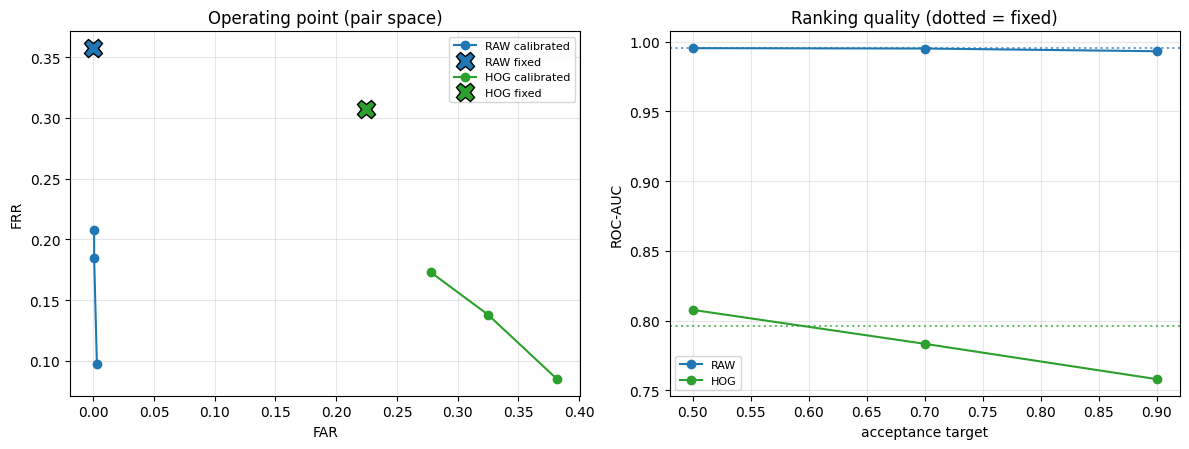

In [16]:
RUN_SWEEP = True
SWEEP_TARGETS = (0.50, 0.70, 0.90)

if RUN_SWEEP:
    sweeps = {}
    for rep in ("RAW","HOG"):
        rows = []
        for t in SWEEP_TARGETS:
            cb = calibrate_corpus_pairspace(rep, target_accept=t, verbose=False)
            _, ov = evaluate_pairspace(rep, cb, f"{rep} t={t:.2f}")
            t3 = int(sum(c["selection_tier"]==3 for c in cb.values()))
            rows.append({**ov, "target_accept": t, "tier3": t3})
            print(f"  {rep} t={t:.2f}  FRR={ov['FRR']:.4f}  FAR={ov['FAR']:.4f}  "
                  f"BalAcc={ov['BalancedAccuracy']:.4f}  AUC={ov['AUC']:.4f}  tier3={t3}", flush=True)
        sweeps[rep] = pd.DataFrame(rows)
    mark("Part 9 sweep")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    for rep, col in [("RAW","tab:blue"), ("HOG","tab:green")]:
        sw = sweeps[rep]
        ax[0].plot(sw["FAR"], sw["FRR"], "o-", color=col, label=f"{rep} calibrated")
        ax[0].plot(pair_base[rep][1]["FAR"], pair_base[rep][1]["FRR"], "X",
                   color=col, markersize=13, markeredgecolor="k", label=f"{rep} fixed")
        ax[1].plot(sw["target_accept"], sw["AUC"], "o-", color=col, label=rep)
        ax[1].axhline(pair_base[rep][1]["AUC"], color=col, linestyle=":", alpha=.7)
    ax[0].set_xlabel("FAR"); ax[0].set_ylabel("FRR"); ax[0].set_title("Operating point (pair space)")
    ax[1].set_xlabel("acceptance target"); ax[1].set_ylabel("ROC-AUC")
    ax[1].set_title("Ranking quality (dotted = fixed)")
    for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
else:
    sweeps = None; print("Sweep skipped.")

---
## Part 10 — Export and runtime report

In [17]:
OUT = Path("/content/drive/MyDrive/4buwan_results_v3"); OUT.mkdir(parents=True, exist_ok=True)
main_table.to_csv(OUT/"table_main_comparison.csv", index=False)
loo_table.to_csv(OUT/"table_loo_acceptance.csv", index=False)
for rep in ("RAW","HOG"):
    pair_base[rep][0].to_csv(OUT/f"per_writer_{rep}_pairspace_fixed.csv", index=False)
    pair_cal[rep][0].to_csv(OUT/f"per_writer_{rep}_pairspace_calibrated.csv", index=False)
    if sweeps: sweeps[rep].to_csv(OUT/f"table_sweep_{rep}.csv", index=False)
pd.DataFrame([{"Representation":rep, "Writer":w, **{k:v for k,v in c.items() if k!="gamma_reference"}}
              for rep, cb in [("RAW",calib_raw),("HOG",calib_hog)] for w,c in cb.items()]
            ).to_csv(OUT/"table_per_writer_calibration.csv", index=False)
print("Saved to", OUT)
for f in sorted(OUT.glob("*.csv")): print("  ", f.name)

Saved to /content/drive/MyDrive/4buwan_results_v3
   per_writer_HOG_pairspace_calibrated.csv
   per_writer_HOG_pairspace_fixed.csv
   per_writer_RAW_pairspace_calibrated.csv
   per_writer_RAW_pairspace_fixed.csv
   table_loo_acceptance.csv
   table_main_comparison.csv
   table_per_writer_calibration.csv
   table_sweep_HOG.csv
   table_sweep_RAW.csv


In [18]:
total = time.time() - NB_T0; h, rem = divmod(total, 3600); m, s = divmod(rem, 60)
print("="*62); print("RUNTIME REPORT")
print("  Environment: Google Colaboratory, Python 3, High-RAM, CPU runtime")
print("  (scikit-learn is CPU-only -- GPU/TPU provide no benefit for OCSVM)")
print("="*62)
for k, v in SECTION_TIMES.items():
    if k == "_last": continue
    print(f"  {k:<40s} {v:8.1f}s  ({v/60:5.1f} min)")
print("-"*62)
print(f"  {'TOTAL':<40s} {total:8.1f}s   =  {int(h)}h {int(m)}m {int(s)}s")
print("="*62)

RUNTIME REPORT
  Environment: Google Colaboratory, Python 3, High-RAM, CPU runtime
  (scikit-learn is CPU-only -- GPU/TPU provide no benefit for OCSVM)
  Part 1a split                                19.2s  (  0.3 min)
  Part 1b features                           1707.7s  ( 28.5 min)
  Part 5 CHECKPOINT A                          13.9s  (  0.2 min)
  Part 6 pair-space baseline                   91.8s  (  1.5 min)
  Part 7 calibration                          192.8s  (  3.2 min)
  Part 8 calibrated eval                       87.6s  (  1.5 min)
  Part 9 sweep                                861.7s  ( 14.4 min)
--------------------------------------------------------------
  TOTAL                                      2975.4s   =  0h 49m 35s


---
## Reported quantities

1. **Checkpoint A (Part 5)** — mean leave-one-out acceptance in pair space, against v2's 0.220 and 0.239.
2. **Part 6** — the pair-space fixed baseline, against the 6buwan signature-space results.
3. **Checkpoint B (Part 8)** — whether calibration exceeds the pair-space fixed baseline, with paired test statistics.
4. **Part 9** — whether the operating-point sweep produces a curve or is flat as in v2.
5. **Part 10** — runtime by section.

## Interpretation of the two checkpoints

| A | B | Interpretation |
|---|---|---|
| PASS | PASS | The representation resolves the geometric constraint and calibration adds to it. Calibration is the primary contribution; the representation is cited prior work. |
| PASS | FAIL | The representation accounts for the improvement. The finding is that representation rather than hyperparameter selection governs one-class signature verification at small enrolment, supported by v2's negative result. |
| FAIL | — | Pair space does not resolve the geometry. The v2 negative result together with this one constitutes a documented diagnosis of why one-class signature verification fails at twelve-signature enrolment. |

Each branch yields an interpretable outcome. Two of the three are negative results.